Task 1

Average Time per Step (minutes):
 Registration            5.804702
Triage                  8.074477
Waiting_for_Doctor     25.775604
Consultation           15.427360
Medication_Printing     4.896163
Checkout                3.837855
Total_Time             63.816161
dtype: float64 

Primary Lean Waste (Bottleneck): Waiting_for_Doctor
Likely Low-Value Step: Medication_Printing


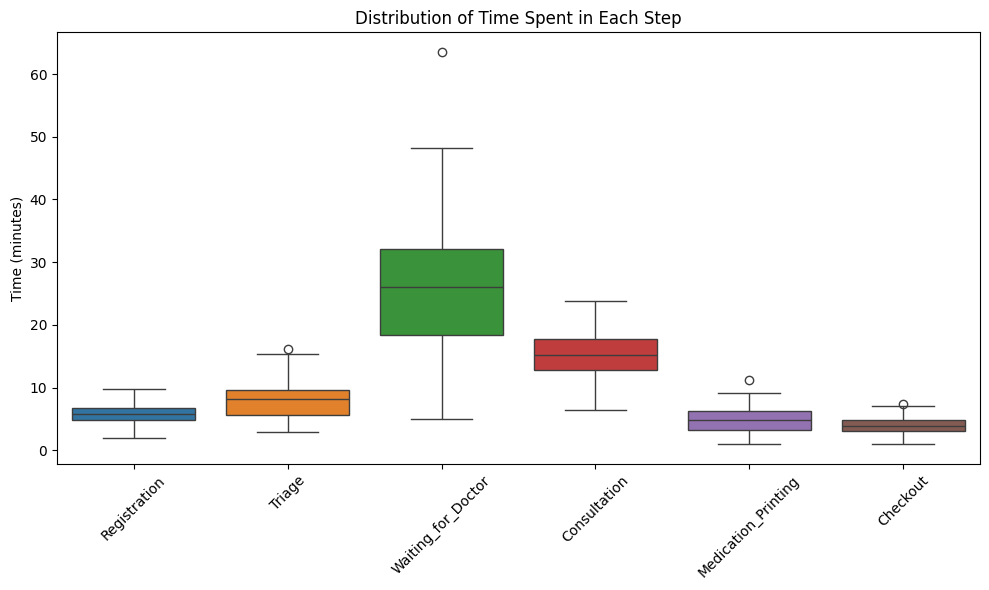

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ----- 1. Simulate Data for 100 Patients -----
np.random.seed(42)
n = 100

data = {
    "Registration": np.random.normal(6, 2, n).clip(2),
    "Triage": np.random.normal(8, 3, n).clip(3),
    "Waiting_for_Doctor": np.random.normal(25, 10, n).clip(5),
    "Consultation": np.random.normal(15, 4, n).clip(5),
    "Medication_Printing": np.random.normal(5, 2, n).clip(1),
    "Checkout": np.random.normal(4, 1.5, n).clip(1),
}

df = pd.DataFrame(data)

# Total time per patient
df["Total_Time"] = df.sum(axis=1)

# ----- 2. Calculate Average Times -----
avg_times = df.mean()
print("Average Time per Step (minutes):\n", avg_times, "\n")

# Identify bottleneck (highest average time)
bottleneck = avg_times.drop("Total_Time").idxmax()

# Identify likely low-value step
low_value_step = "Medication_Printing"

# ----- REQUIRED PRINTED OUTPUTS -----
print("Primary Lean Waste (Bottleneck):", bottleneck)
print("Likely Low-Value Step:", low_value_step)

# ----- 3. Boxplot Visualization -----
plt.figure(figsize=(10,6))
sns.boxplot(data=df.drop(columns="Total_Time"))
plt.title("Distribution of Time Spent in Each Step")
plt.ylabel("Time (minutes)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


The main bottleneck is Waiting_for_Doctor, showing a clear Lean waste of waiting. This can be reduced through workload leveling (Heijunka) to smooth patient flow, better triage-to-provider signaling to speed handoffs, and optimized scheduling templates to prevent provider overload.
Medication_Printing is a low-value administrative step and should be automated or integrated into consultation to eliminate unnecessary activity.

Task 2

Average Occupancy (Last 30 Days): 80.13%
Number of Days Over 90% Occupancy: 11


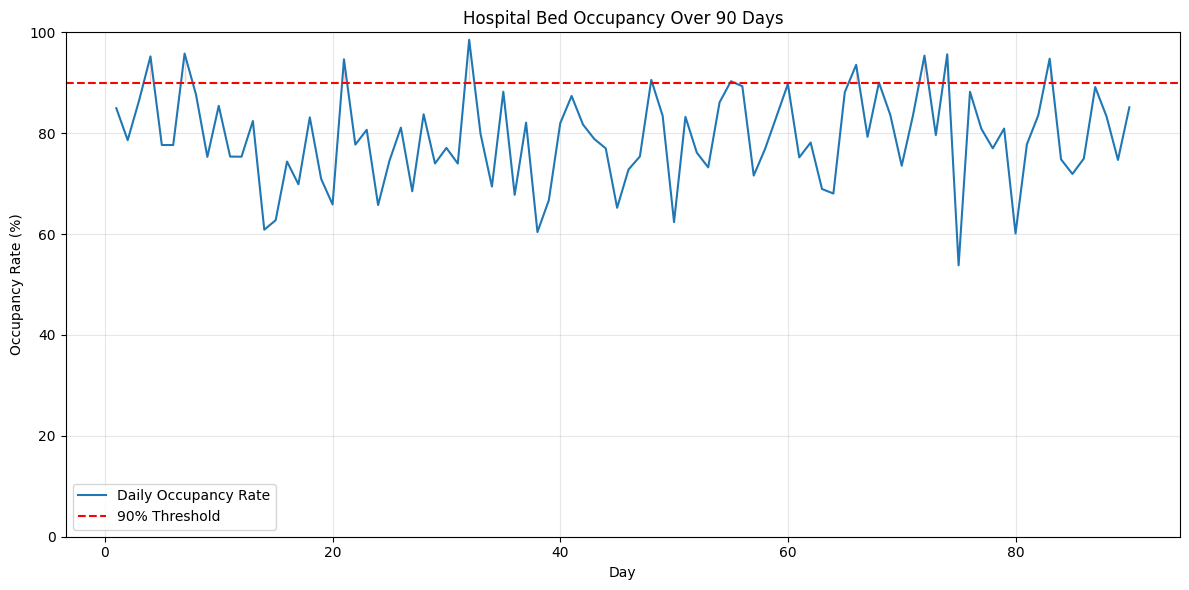

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----- 1. Simulate 90 Days of Bed Usage -----
np.random.seed(42)
days = 90
total_beds = 100

# Simulate bed usage (realistic: fluctuates between 60–100 beds)
bed_usage = np.random.normal(loc=80, scale=10, size=days).clip(50, 100)

# Create DataFrame
df = pd.DataFrame({
    "Day": range(1, days + 1),
    "Beds_Used": bed_usage
})

# ----- 2. Calculate Occupancy Metrics -----
df["Occupancy_Rate"] = df["Beds_Used"] / total_beds * 100

# Average occupancy over last 30 days
avg_30_day_occupancy = df["Occupancy_Rate"].tail(30).mean()

# Count days over 90% occupancy
days_over_90 = (df["Occupancy_Rate"] > 90).sum()

print("Average Occupancy (Last 30 Days): {:.2f}%".format(avg_30_day_occupancy))
print("Number of Days Over 90% Occupancy:", days_over_90)

# ----- 3. Visualization -----
plt.figure(figsize=(12,6))
plt.plot(df["Day"], df["Occupancy_Rate"], label="Daily Occupancy Rate")

# Shaded threshold
plt.axhline(90, color='red', linestyle='--', label="90% Threshold")
plt.fill_between(df["Day"], 90, df["Occupancy_Rate"],
                 where=(df["Occupancy_Rate"] > 90),
                 color='red', alpha=0.2)

plt.title("Hospital Bed Occupancy Over 90 Days")
plt.xlabel("Day")
plt.ylabel("Occupancy Rate (%)")
plt.ylim(0, 100)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


To reduce risk, the hospital should improve discharge efficiency, smooth elective surgery scheduling, and strengthen coordination with step-down or community care options to accelerate safe patient transitions. Implementing predictive bed-management tools and establishing rapid-turnover or flex-capacity protocols can further enhance resilience during periods of high census

Task 3


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

In [ ]:

from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
df = pd.read_csv("raw_weekly_hospital_respiratory_data_2020_2024.csv")

df = df[[
    "Week Ending Date",
    "Percent Inpatient Beds Occupied",
    "Percent ICU Beds Occupied"
]].copy()

df.columns = ["Week", "Inpatient_Occ", "ICU_Occ"]

df["Week"] = pd.to_datetime(df["Week"])
df = df.sort_values("Week").reset_index(drop=True)

df.head()

,Week,Inpatient_Occ,ICU_Occ
0,2020-08-08,0.68,0.49
1,2020-08-08,0.59,0.53
2,2020-08-08,0.64,0.55
3,2020-08-08,0.76,0.41
4,2020-08-08,0.69,0.59


from matplotlib import pyplot as plt
_df_0['index'].plot(kind='hist', bins=20, title='index')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_1['Inpatient_Occ'].plot(kind='hist', bins=20, title='Inpatient_Occ')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_2['ICU_Occ'].plot(kind='hist', bins=20, title='ICU_Occ')
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_3.plot(kind='scatter', x='index', y='Inpatient_Occ', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

from matplotlib import pyplot as plt
_df_4.plot(kind='scatter', x='Inpatient_Occ', y='ICU_Occ', s=32, alpha=.8)
plt.gca().spines[['top', 'right',]].set_visible(False)

... (2 outputs left out)

from matplotlib import pyplot as plt
import seaborn as sns
def _plot_series(series, series_name, series_index=0):
  palette = list(sns.palettes.mpl_palette('Dark2'))
  counted = (series['index']
                .value_counts()
              .reset_index(name='counts')
              .rename({'index': 'index'}, axis=1)
              .sort_values('index', ascending=True))
  xs = counted['index']
  ys = counted['counts']
  plt.plot(xs, ys, label=series_name, color=palette[series_index % len(palette)])

fig, ax = plt.subplots(figsize=(10, 5.2), layout='constrained')
df_sorted = _df_7.sort_values('index', ascending=True)
_plot_series(df_sorted, '')
sns.despine(fig=fig, ax=ax)
plt.xlabel('index')
_ = plt.ylabel('count()')

from matplotlib import pyplot as plt
_df_8['index'].plot(kind='line', figsize=(8, 4), title='index')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_9['Inpatient_Occ'].plot(kind='line', figsize=(8, 4), title='Inpatient_Occ')
plt.gca().spines[['top', 'right']].set_visible(False)

from matplotlib import pyplot as plt
_df_10['ICU_Occ'].plot(kind='line', figsize=(8, 4), title='ICU_Occ')
plt.gca().spines[['top', 'right']].set_visible(False)

In [ ]:
df = pd.read_csv("raw_weekly_hospital_respiratory_data_2020_2024.csv")

df = df[[
    "Week Ending Date",
    "Percent Inpatient Beds Occupied",
    "Percent ICU Beds Occupied"
]].copy()

df.columns = ["Week", "Inpatient_Occ", "ICU_Occ"]

df["Week"] = pd.to_datetime(df["Week"])

# Convert fractions → percentages
df["Inpatient_Occ"] = pd.to_numeric(df["Inpatient_Occ"], errors="coerce") * 100
df["ICU_Occ"] = pd.to_numeric(df["ICU_Occ"], errors="coerce") * 100

# Remove impossible values
df.loc[df["Inpatient_Occ"] > 100, "Inpatient_Occ"] = np.nan
df.loc[df["Inpatient_Occ"] < 0, "Inpatient_Occ"] = np.nan

df.loc[df["ICU_Occ"] > 100, "ICU_Occ"] = np.nan
df.loc[df["ICU_Occ"] < 0, "ICU_Occ"] = np.nan

# Fill missing values
df = df.sort_values("Week")
df["Inpatient_Occ"] = df["Inpatient_Occ"].fillna(method="ffill")
df["ICU_Occ"] = df["ICU_Occ"].fillna(method="ffill")

df = df.reset_index(drop=True)

/tmp/ipython-input-4168225075.py:26: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["Inpatient_Occ"] = df["Inpatient_Occ"].fillna(method="ffill")
/tmp/ipython-input-4168225075.py:27: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["ICU_Occ"] = df["ICU_Occ"].fillna(method="ffill")


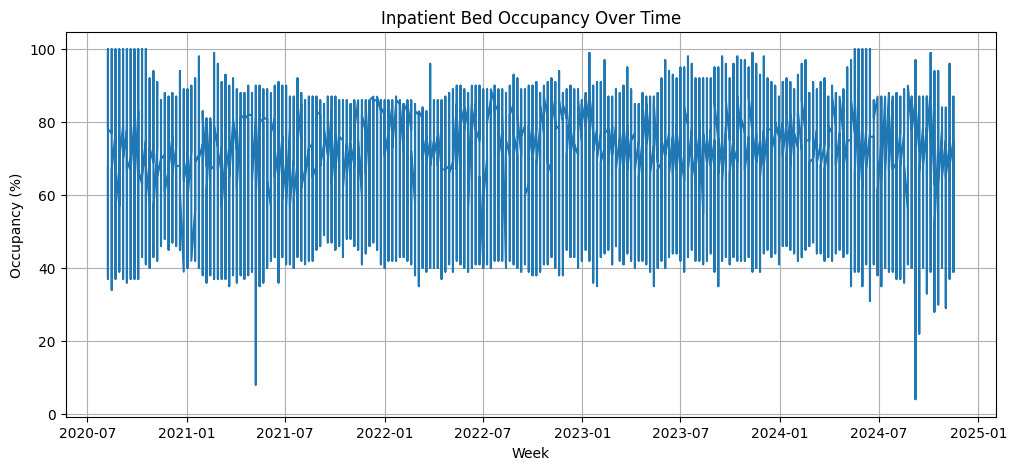

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(df["Week"], df["Inpatient_Occ"])
plt.title("Inpatient Bed Occupancy Over Time")
plt.xlabel("Week")
plt.ylabel("Occupancy (%)")
plt.grid()
plt.show()

In [ ]:
avg_occ = df["Inpatient_Occ"].mean()
print("Average Occupancy:", round(avg_occ,2), "%")
high_weeks = (df["Inpatient_Occ"] > 90).sum()
print("Weeks Above 90% Occupancy:", high_weeks)

Average Occupancy: 71.78 %
Weeks Above 90% Occupancy: 115


/tmp/ipython-input-4154247095.py:46: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["Inpatient_Occ"] = df["Inpatient_Occ"].fillna(method="ffill")
/tmp/ipython-input-4154247095.py:47: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["ICU_Occ"] = df["ICU_Occ"].fillna(method="ffill")
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


samples total: 218 | train: 174 | test: 44


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
22/22 - 5s - 230ms/step - loss: 0.1114 - val_loss: 0.0540
Epoch 2/100
22/22 - 0s - 9ms/step - loss: 0.0173 - val_loss: 0.0126
Epoch 3/100
22/22 - 0s - 9ms/step - loss: 0.0094 - val_loss: 0.0145
Epoch 4/100
22/22 - 0s - 10ms/step - loss: 0.0108 - val_loss: 0.0148
Epoch 5/100
22/22 - 0s - 11ms/step - loss: 0.0096 - val_loss: 0.0145
Epoch 6/100
22/22 - 0s - 9ms/step - loss: 0.0094 - val_loss: 0.0154
Epoch 7/100
22/22 - 0s - 9ms/step - loss: 0.0104 - val_loss: 0.0149
Epoch 8/100
22/22 - 0s - 14ms/step - loss: 0.0099 - val_loss: 0.0158
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step

Test RMSE: 1.424
Test MAE:  0.976


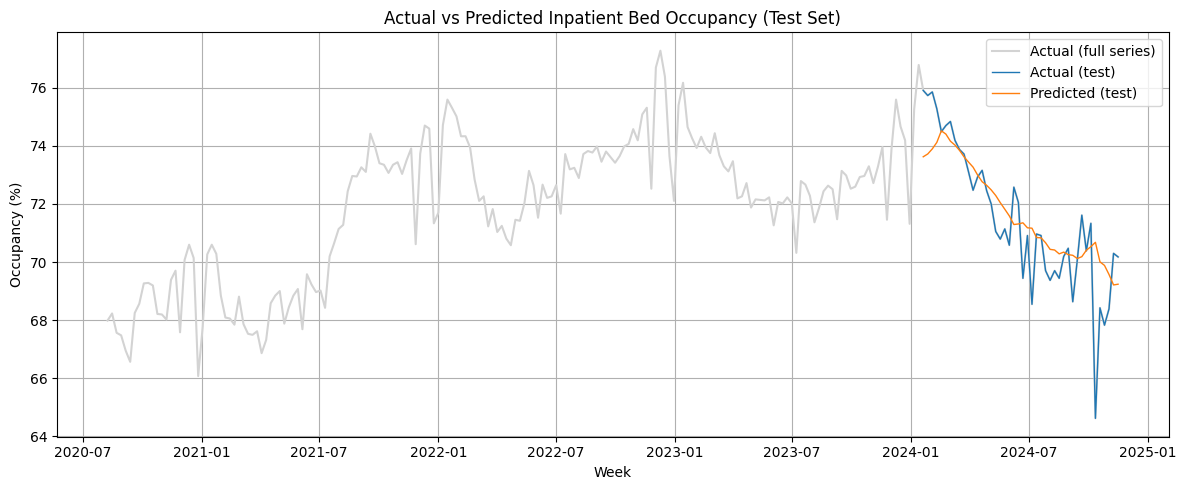

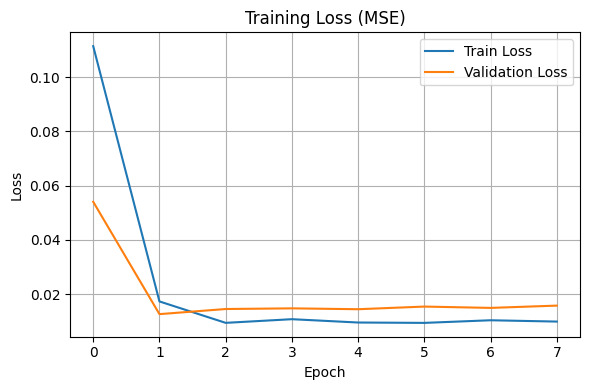


Sample predictions (test):
      Week    Actual  Predicted
2024-01-20 75.912281  73.626434
2024-01-27 75.736842  73.723297
2024-02-03 75.859649  73.897903
2024-02-10 75.280702  74.121170
2024-02-17 74.491228  74.520416
2024-02-24 74.701754  74.408066
2024-03-02 74.842105  74.163330
2024-03-09 74.192982  74.029640
2024-03-16 73.877193  73.849426
2024-03-23 73.719298  73.624832


In [ ]:
df = pd.read_csv("raw_weekly_hospital_respiratory_data_2020_2024.csv")

# Keep only required columns
df = df[[
    "Week Ending Date",
    "Percent Inpatient Beds Occupied",
    "Percent ICU Beds Occupied"
]].copy()

# Rename columns
df.columns = ["Week", "Inpatient_Occ", "ICU_Occ"]

df["Week"] = pd.to_datetime(df["Week"], errors="coerce")

# Convert raw fractions to percentage (CDC stores as 0.70 → 70%)
df["Inpatient_Occ"] = pd.to_numeric(df["Inpatient_Occ"], errors="coerce") * 100
df["ICU_Occ"] = pd.to_numeric(df["ICU_Occ"], errors="coerce") * 100

# Remove impossible values
df.loc[df["Inpatient_Occ"] > 100, "Inpatient_Occ"] = np.nan
df.loc[df["Inpatient_Occ"] < 0, "Inpatient_Occ"] = np.nan
df.loc[df["ICU_Occ"] > 100, "ICU_Occ"] = np.nan
df.loc[df["ICU_Occ"] < 0, "ICU_Occ"] = np.nan

# Sort
df = df.sort_values("Week")

# Fix missing by forward-fill
df["Inpatient_Occ"] = df["Inpatient_Occ"].fillna(method="ffill")
df["ICU_Occ"] = df["ICU_Occ"].fillna(method="ffill")


df = df.groupby("Week", as_index=False).mean().sort_values("Week").reset_index(drop=True)


series = df[['Week', 'Inpatient_Occ']].copy()

scaler = MinMaxScaler(feature_range=(0,1))
scaled_values = scaler.fit_transform(series[['Inpatient_Occ']].values)

look_back = 6
X, y, dates = [], [], []

for i in range(look_back, len(scaled_values)):
    X.append(scaled_values[i-look_back:i, 0])   # previous 6 weeks
    y.append(scaled_values[i, 0])               # next week
    dates.append(series.loc[i, 'Week'])

X = np.array(X).reshape(-1, look_back, 1)
y = np.array(y)
dates = np.array(dates)
split_frac = 0.8
split_idx = int(len(X) * split_frac)

X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
dates_train, dates_test = dates[:split_idx], dates[split_idx:]

print(f"samples total: {len(X)} | train: {len(X_train)} | test: {len(X_test)}")


# 7. BUILD MODEL
model = Sequential([
    LSTM(64, input_shape=(look_back,1), return_sequences=False),
    Dropout(0.1),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.summary()

es = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)

history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=100,
    batch_size=8,
    callbacks=[es],
    verbose=2
)


# MAKE PREDICTIONS
pred_train_scaled = model.predict(X_train)
pred_test_scaled  = model.predict(X_test)

pred_train = scaler.inverse_transform(pred_train_scaled)
pred_test  = scaler.inverse_transform(pred_test_scaled)
real_train = scaler.inverse_transform(y_train.reshape(-1,1))
real_test  = scaler.inverse_transform(y_test.reshape(-1,1))

rmse = np.sqrt(mean_squared_error(real_test, pred_test))
mae  = mean_absolute_error(real_test, pred_test)

print(f"\nTest RMSE: {rmse:.3f}")
print(f"Test MAE:  {mae:.3f}")

df_preds_test = pd.DataFrame({
    "Week": dates_test,
    "Actual": real_test.flatten(),
    "Predicted": pred_test.flatten()
})

df_preds_train = pd.DataFrame({
    "Week": dates_train,
    "Actual": real_train.flatten(),
    "Predicted": pred_train.flatten()
})

plt.figure(figsize=(12,5))
plt.plot(series["Week"], series["Inpatient_Occ"], label="Actual (full series)", color="lightgray")
plt.plot(df_preds_test["Week"], df_preds_test["Actual"], label="Actual (test)", linewidth=1)
plt.plot(df_preds_test["Week"], df_preds_test["Predicted"], label="Predicted (test)", linewidth=1)
plt.title("Actual vs Predicted Inpatient Bed Occupancy (Test Set)")
plt.xlabel("Week")
plt.ylabel("Occupancy (%)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# PLOT — LOSS CURVE
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Training Loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()
print("\nSample predictions (test):")
print(df_preds_test.head(10).to_string(index=False))
